In [16]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("/home/abdulhay/project/Notebook/pro9/data/raw/train.csv")

# `OverView`

In [2]:
df.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  str    
 9   City_Type                    668665 non-null  str    
 10  Current_Car_Type             668665 non-null  str    
 11  Home_Charging_Possible       668665 non-null  str    
 12  Subsidy_Available            668665 non-null  str    
 13  Range_Anxi

In [5]:
df.duplicated().sum()

np.int64(0)

In [10]:
cat_cols = df.select_dtypes("str").columns.tolist()
num_cols = df.select_dtypes("number").columns.tolist()

In [6]:
print(df['Will_Buy_EV'].value_counts(normalize=True) * 100)

Will_Buy_EV
No     82.5355
Yes    17.4645
Name: proportion, dtype: float64


In [13]:
for col in cat_cols:
    print(f"{col}: {df[col].unique()}")
    print()
    print(f"{col}: {df[col].value_counts()}")
    print()
    print("-"*40)
df.describe()

Gender: <StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

Gender: Gender
Male      367954
Female    295427
Other       5284
Name: count, dtype: int64

----------------------------------------
City_Type: <StringArray>
['Suburban', 'Rural', 'Urban']
Length: 3, dtype: str

City_Type: City_Type
Urban       289305
Suburban    255377
Rural       123983
Name: count, dtype: int64

----------------------------------------
Current_Car_Type: <StringArray>
['Sedan', 'SUV', 'Hatchback', 'Truck']
Length: 4, dtype: str

Current_Car_Type: Current_Car_Type
Sedan        303459
SUV          246545
Hatchback     79438
Truck         39223
Name: count, dtype: int64

----------------------------------------
Home_Charging_Possible: <StringArray>
['Yes', 'No']
Length: 2, dtype: str

Home_Charging_Possible: Home_Charging_Possible
Yes    462677
No     205988
Name: count, dtype: int64

----------------------------------------
Subsidy_Available: <StringArray>
['No', 'Yes']
Length: 2, dtype: str

Sub

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level
count,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000
mean,334332.000000,47.039171,84769.266989,32.158298,1.712626,4.960408,7.176314,2.935477
std,193027.103211,12.875448,28648.029042,18.730474,0.729275,3.926843,5.186627,1.429119
min,0.000000,25.000000,30000.000000,5.000000,1.000000,0.000000,0.000000,1.000000
25%,167166.000000,36.000000,67376.000000,17.200000,1.000000,2.000000,3.000000,2.000000
50%,334332.000000,47.000000,84880.000000,33.600000,2.000000,4.000000,6.000000,3.000000
75%,501498.000000,58.000000,102753.000000,47.400000,2.000000,7.000000,10.000000,4.000000
max,668664.000000,69.000000,188549.000000,98.700000,4.000000,14.000000,19.000000,5.000000


# `EDA` **Univariate Analysis**

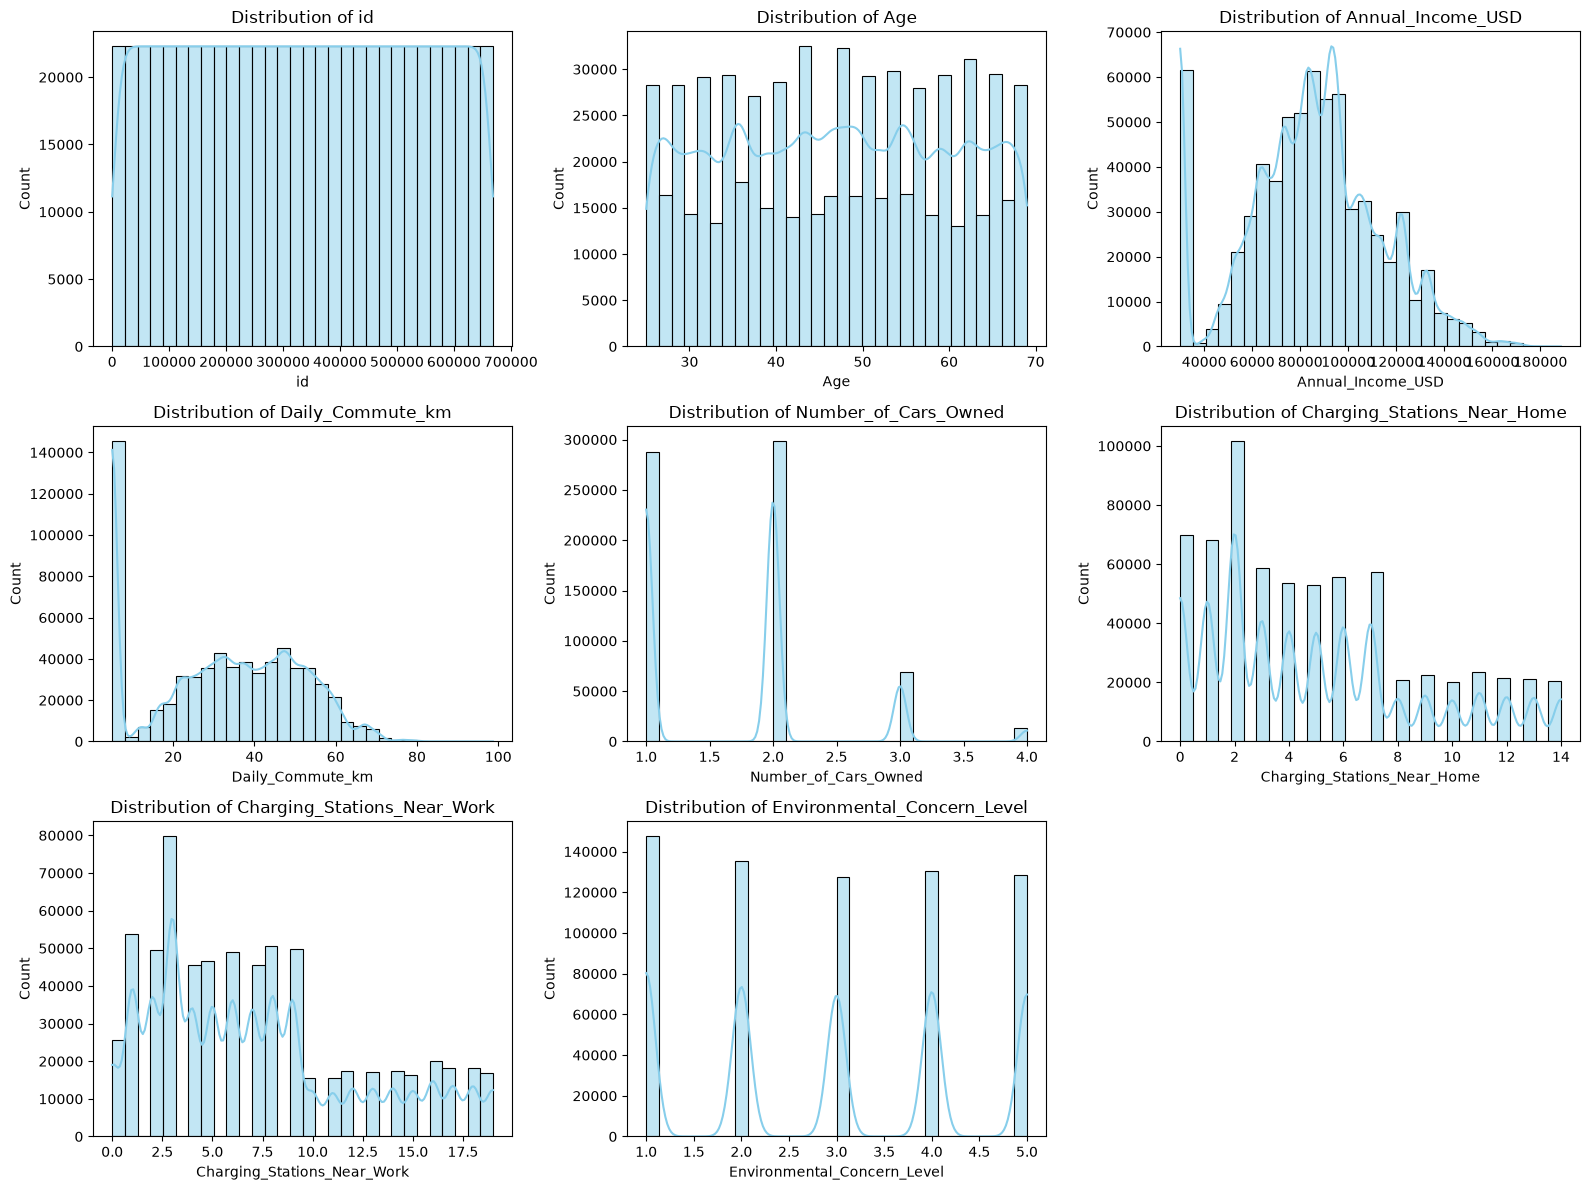

In [14]:
plt.figure(figsize=(16, 12))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[col], kde=True, bins=30, color='skyblue')
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

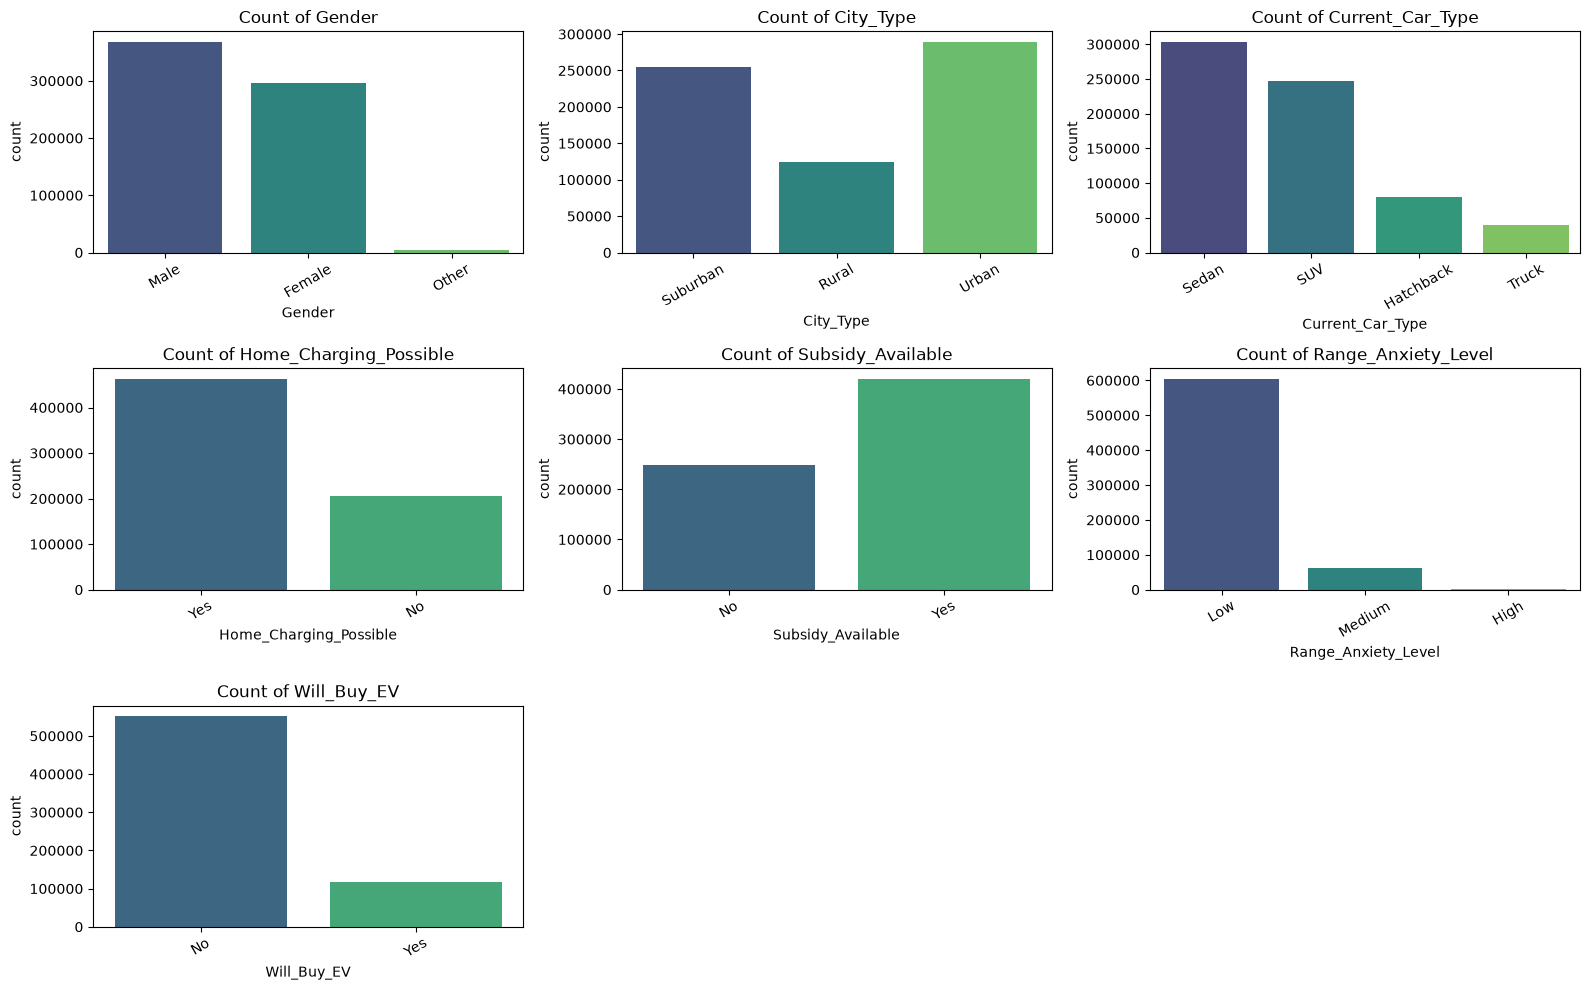

In [17]:
plt.figure(figsize=(16, 10))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(3, 3, i)
    sns.countplot(data=df, x=col, palette='viridis')
    plt.title(f'Count of {col}')
    plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# `Bivariate Analysis`

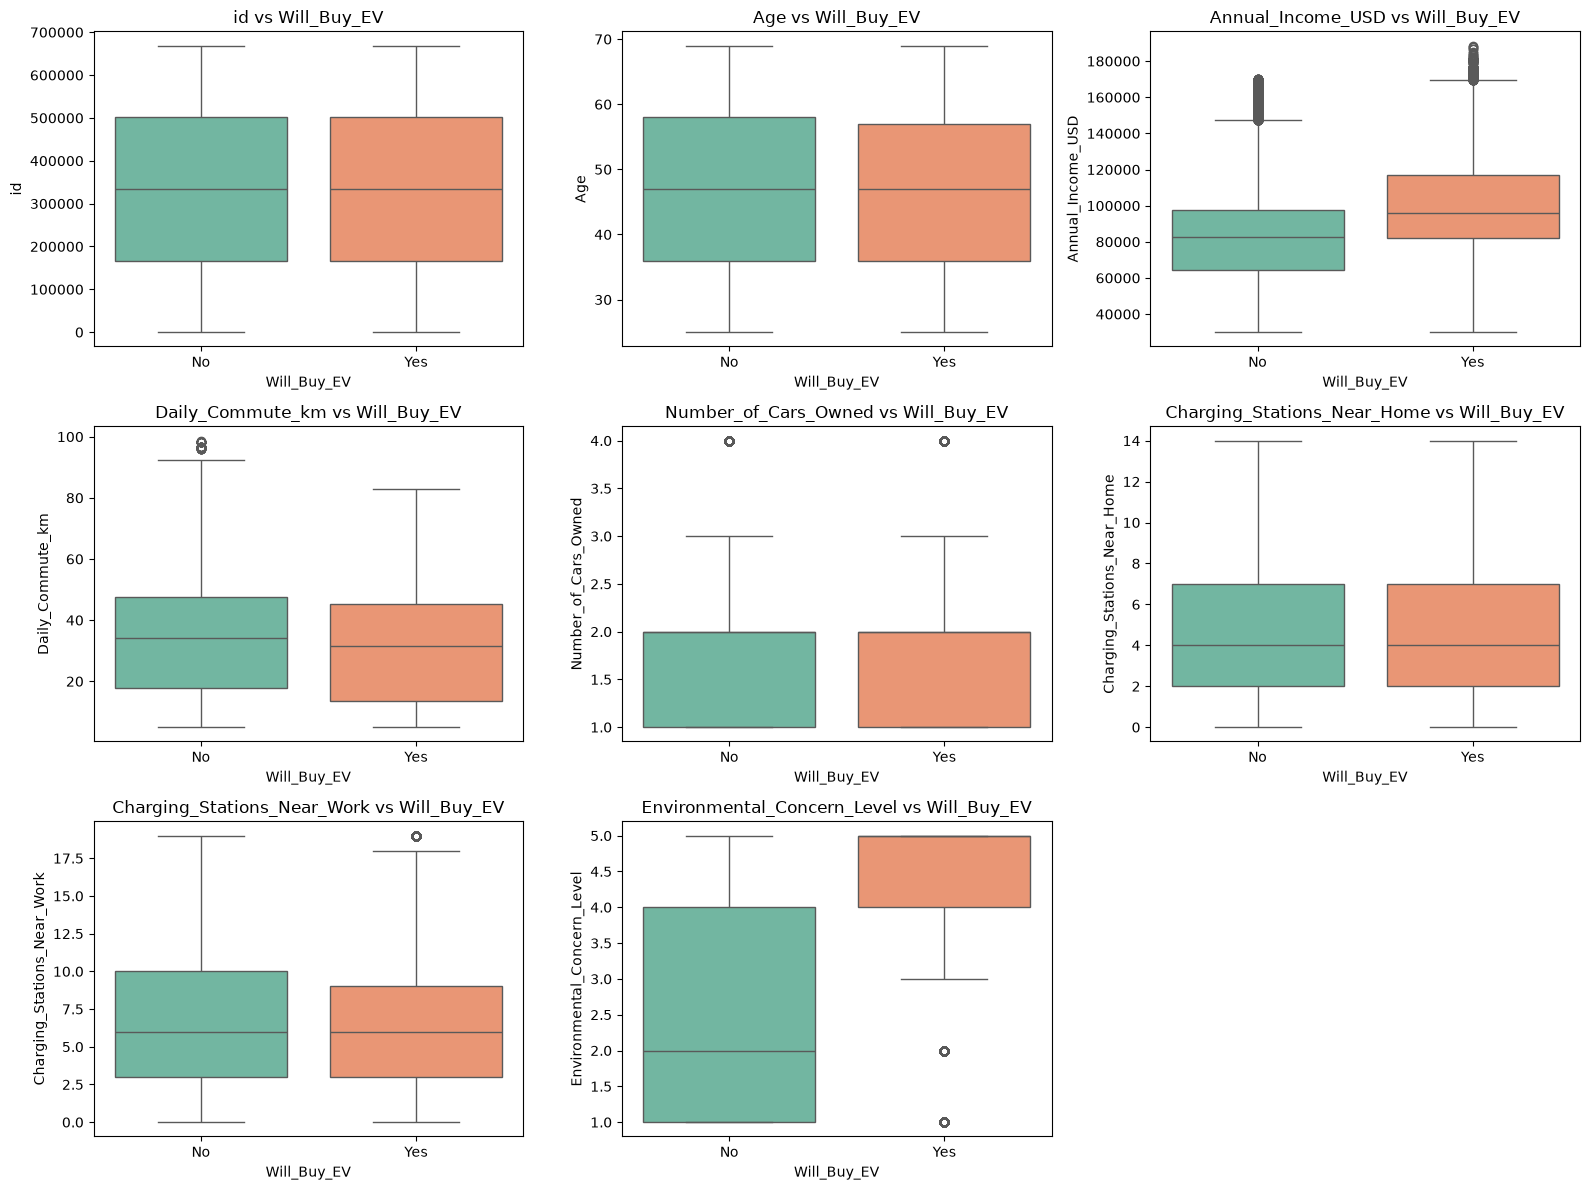

In [18]:
plt.figure(figsize=(16, 12))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(data=df, x='Will_Buy_EV', y=col, palette='Set2')
    plt.title(f'{col} vs Will_Buy_EV')
plt.tight_layout()
plt.show()

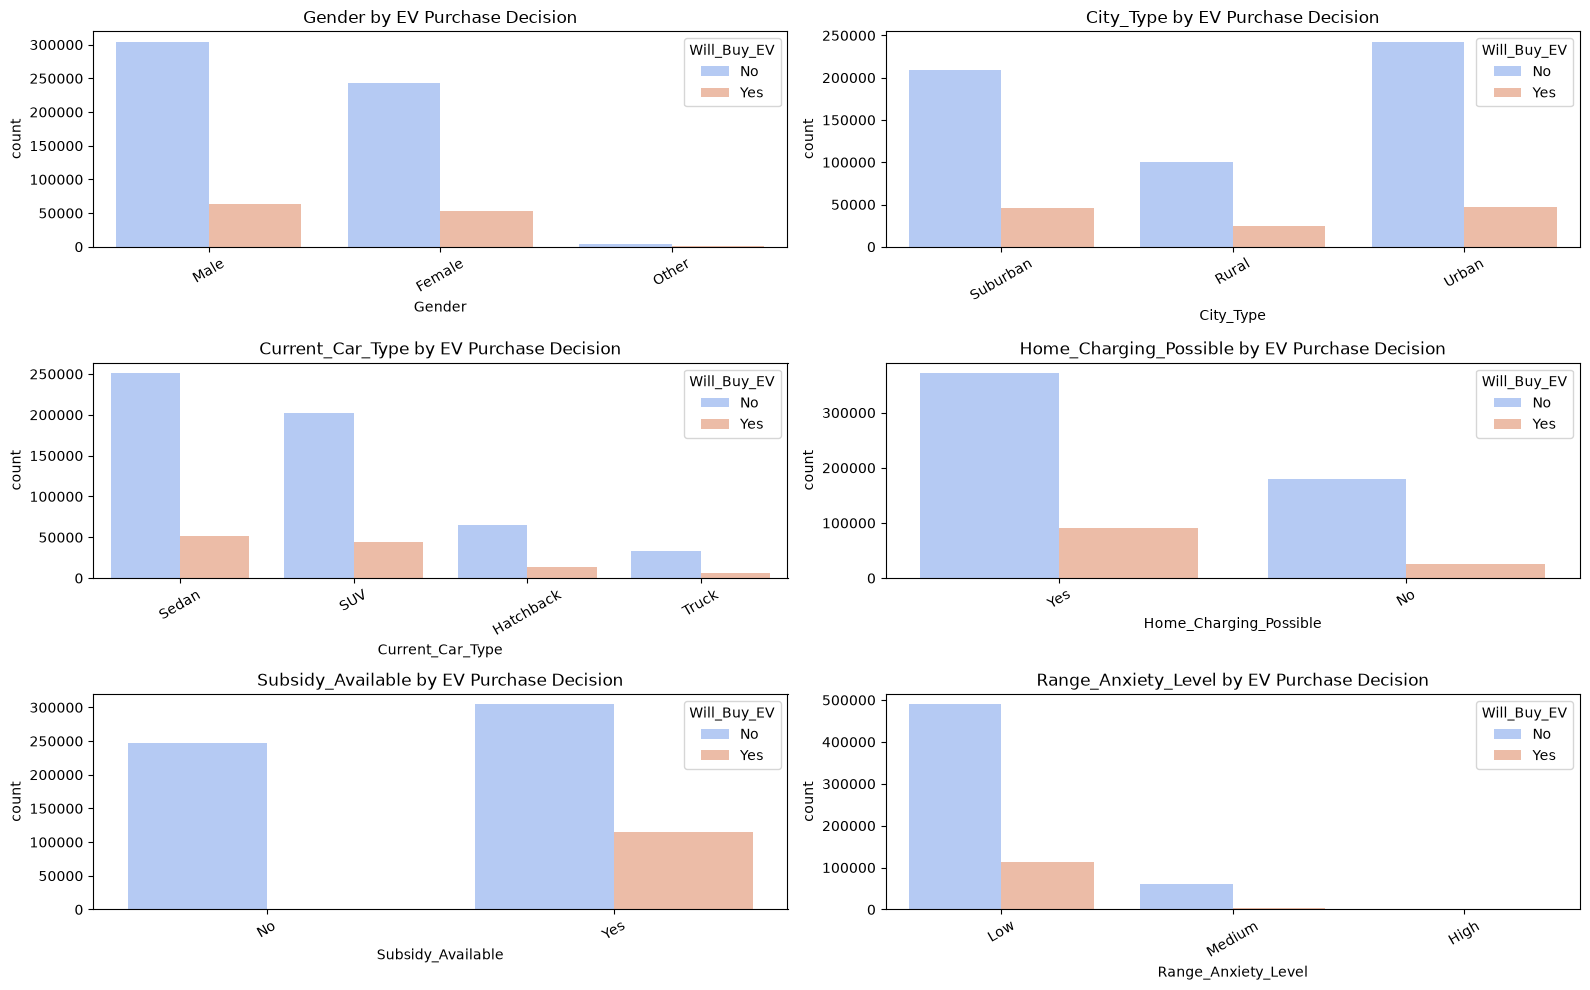

In [19]:
plt.figure(figsize=(16, 10))
for i, col in enumerate(cat_cols[:-1], 1):   
    plt.subplot(3, 2, i)
    sns.countplot(data=df, x=col, hue='Will_Buy_EV', palette='coolwarm')
    plt.title(f'{col} by EV Purchase Decision')
    plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# `MultiVariat Analysis`

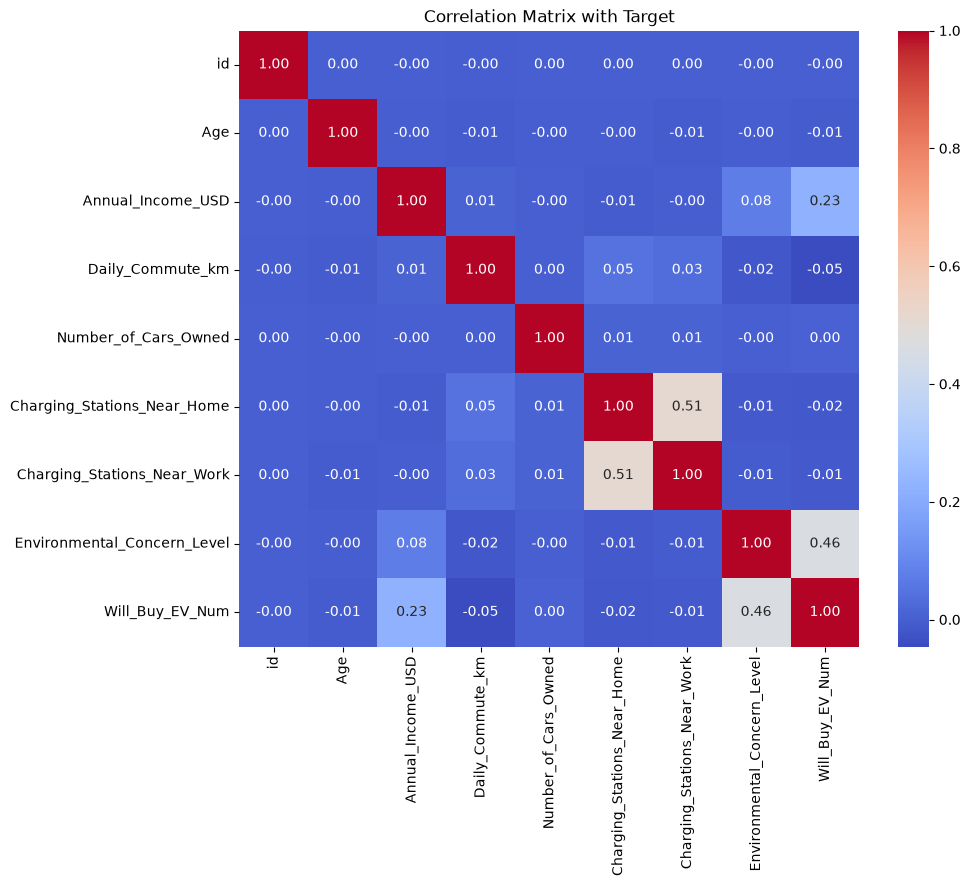

In [20]:
df_corr = df.copy()
df_corr['Will_Buy_EV_Num'] = df_corr['Will_Buy_EV'].map({'Yes': 1, 'No': 0, '1': 1, '0': 0})

plt.figure(figsize=(10, 8))
sns.heatmap(df_corr[num_cols + ['Will_Buy_EV_Num']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix with Target')
plt.show()

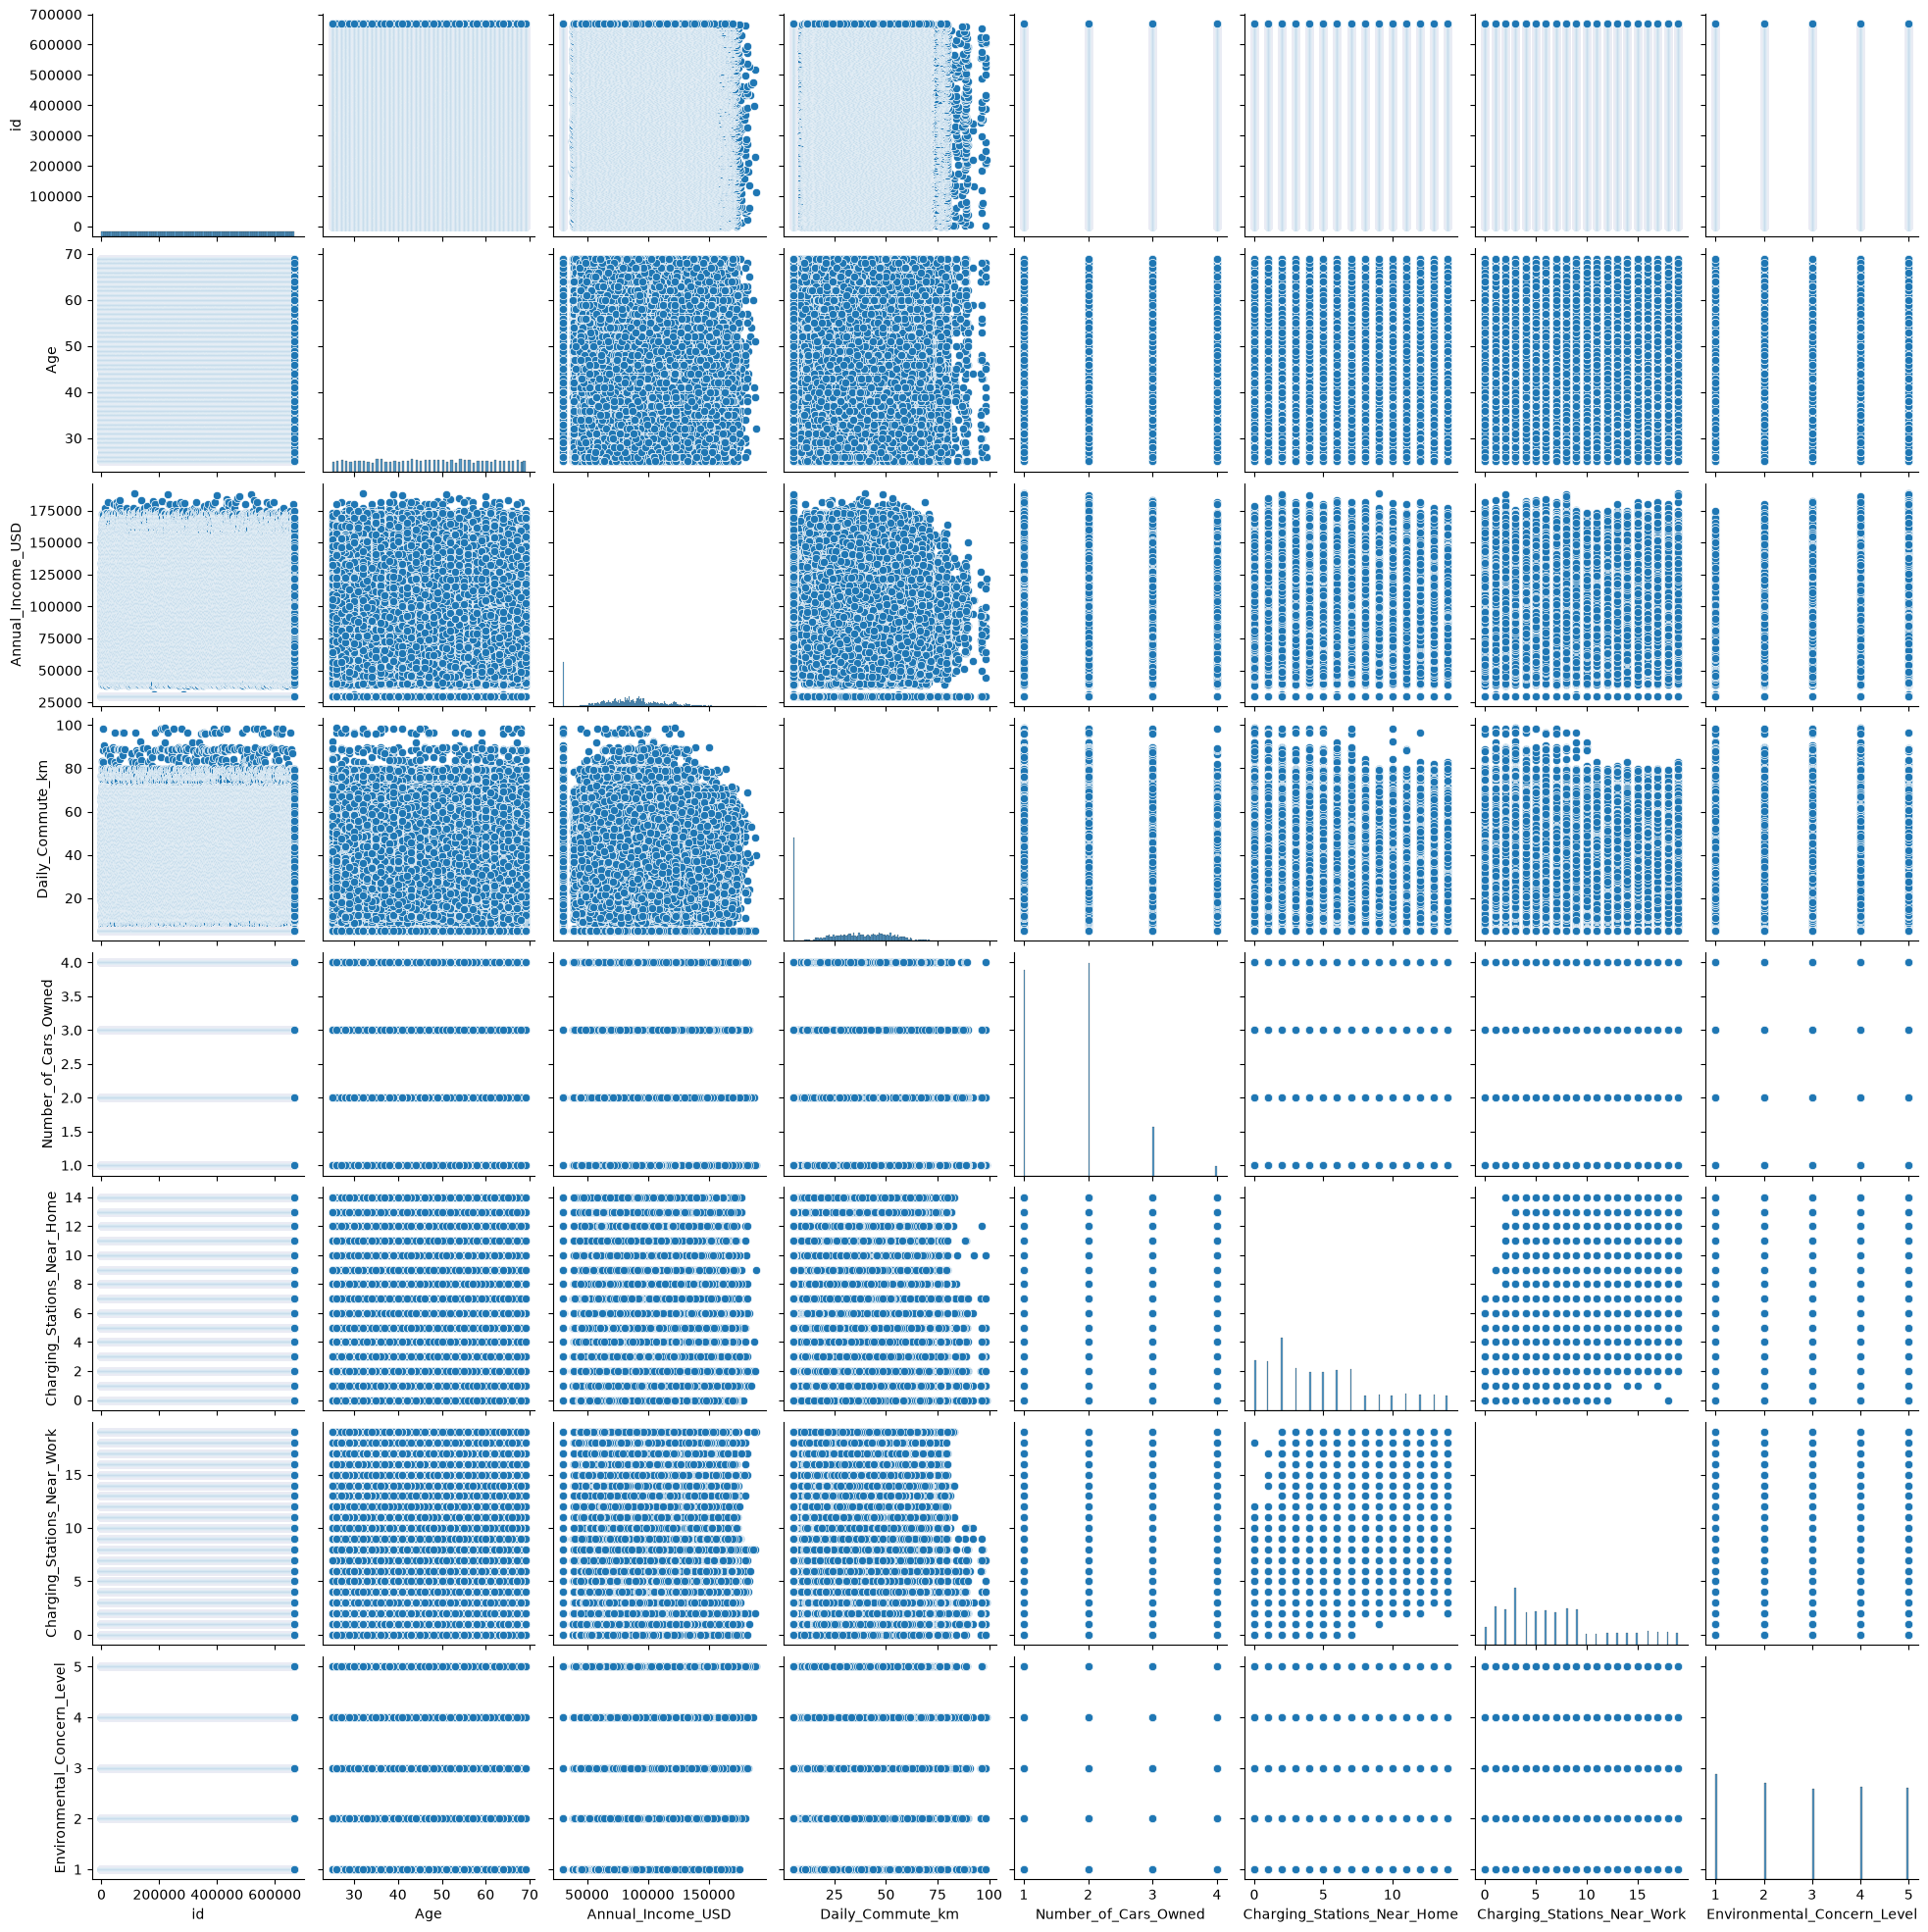

In [21]:
sns.pairplot(df)
plt.show()